# Titanic – Machine Learning from Disaster

In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Load the datasets
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

In [3]:
print(train.shape)
print(test.shape)

(891, 12)
(418, 11)


In [4]:
train.info

<bound method DataFrame.info of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                   

In [5]:
train.describe

<bound method NDFrame.describe of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                 

In [6]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
train.duplicated().sum()

np.int64(0)

In [8]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [10]:
train["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

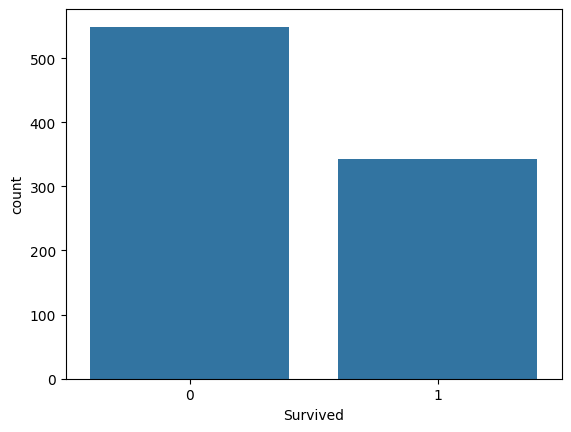

In [11]:
sns.countplot(data=train, x="Survived")
plt.show()

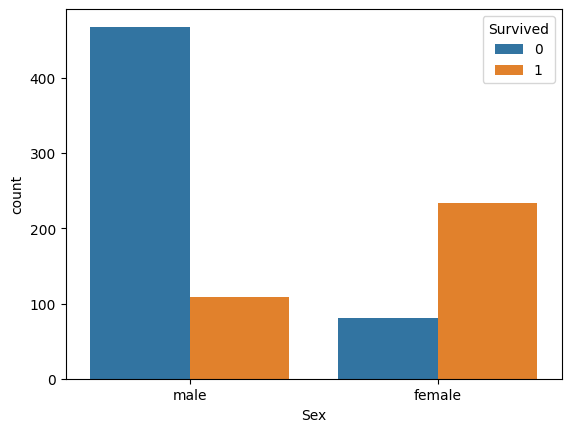

In [12]:
sns.countplot(data=train, x="Sex", hue="Survived")
plt.show()

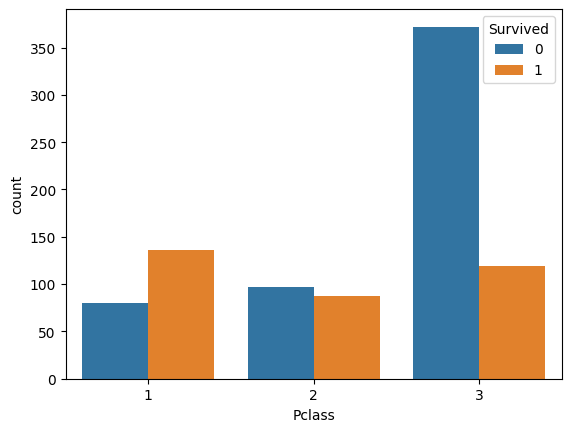

In [13]:
sns.countplot(data=train, x="Pclass", hue="Survived")
plt.show()

In [14]:
X = train.drop("Survived", axis=1)
y = train["Survived"]

In [15]:
X = X.drop(["PassengerId", "Name", "Ticket", "Cabin"], axis=1)

test_id = test["PassengerId"]

test = test.drop(["PassengerId", "Name", "Ticket", "Cabin"], axis=1)

In [16]:
num_cols = X.select_dtypes(include=np.number).columns

cat_cols = X.select_dtypes(include="object").columns

print(num_cols)
print(cat_cols)

Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')
Index(['Sex', 'Embarked'], dtype='object')


In [17]:
from sklearn.impute import SimpleImputer

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

X[num_cols] = num_imputer.fit_transform(X[num_cols])
test[num_cols] = num_imputer.transform(test[num_cols])

X[cat_cols] = cat_imputer.fit_transform(X[cat_cols])
test[cat_cols] = cat_imputer.transform(test[cat_cols])

In [18]:
X = pd.get_dummies(X, drop_first=True)
test = pd.get_dummies(test, drop_first=True)

test = test.reindex(columns=X.columns, fill_value=0)

In [19]:
X.head

<bound method NDFrame.head of      Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  Embarked_S
0       3.0  22.0    1.0    0.0   7.2500      True       False        True
1       1.0  38.0    1.0    0.0  71.2833     False       False       False
2       3.0  26.0    0.0    0.0   7.9250     False       False        True
3       1.0  35.0    1.0    0.0  53.1000     False       False        True
4       3.0  35.0    0.0    0.0   8.0500      True       False        True
..      ...   ...    ...    ...      ...       ...         ...         ...
886     2.0  27.0    0.0    0.0  13.0000      True       False        True
887     1.0  19.0    0.0    0.0  30.0000     False       False        True
888     3.0  28.0    1.0    2.0  23.4500     False       False        True
889     1.0  26.0    0.0    0.0  30.0000      True       False       False
890     3.0  32.0    0.0    0.0   7.7500      True        True       False

[891 rows x 8 columns]>

In [20]:
X.isnull().sum()

Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64

In [21]:
X.shape, test.shape

((891, 8), (418, 8))

In [22]:
y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [26]:
lr = LogisticRegression(max_iter=1000)

In [27]:
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [28]:
y_pred = lr.predict(X_test)

In [29]:
accuracy_score(y_test, y_pred)

0.8044692737430168

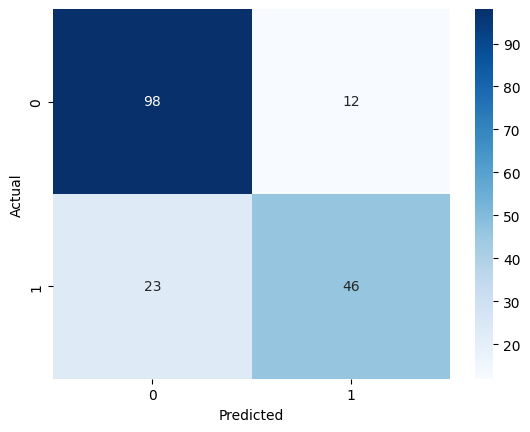

In [30]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [31]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [32]:
lr.predict_proba(X_test[:10])

array([[0.93374384, 0.06625616],
       [0.95342876, 0.04657124],
       [0.84840028, 0.15159972],
       [0.96520361, 0.03479639],
       [0.31638207, 0.68361793],
       [0.55539745, 0.44460255],
       [0.24395899, 0.75604101],
       [0.67392797, 0.32607203],
       [0.65649221, 0.34350779],
       [0.84093315, 0.15906685]])

In [33]:
lr_accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", lr_accuracy * 100)

Logistic Regression Accuracy: 80.44692737430168


# Decision Tree

In [34]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [35]:
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

In [36]:
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,10
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [37]:
y_pred_dt = dt.predict(X_test)

In [38]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy * 100)

Decision Tree Accuracy: 77.09497206703911


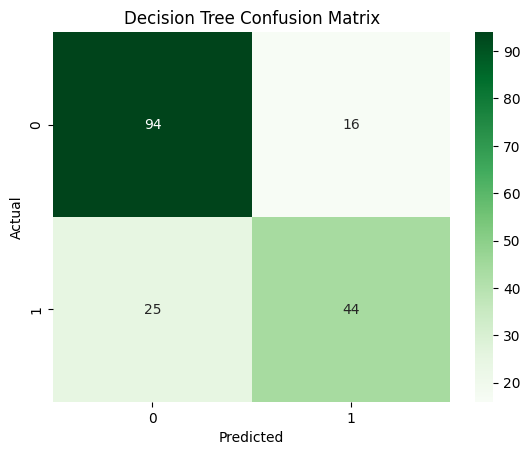

In [39]:
cm = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [40]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.79      0.85      0.82       110
           1       0.73      0.64      0.68        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179



In [41]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

      Feature  Importance
5    Sex_male    0.547677
0      Pclass    0.190506
4        Fare    0.121417
1         Age    0.102602
7  Embarked_S    0.035351
2       SibSp    0.001678
3       Parch    0.000769
6  Embarked_Q    0.000000


In [42]:
print("Logistic Regression:", lr_accuracy * 100)
print("Decision Tree:", dt_accuracy * 100)

Logistic Regression: 80.44692737430168
Decision Tree: 77.09497206703911


# Random forest classifire

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [44]:
rf = RandomForestClassifier(
    n_estimators=200,
    criterion="gini",
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    random_state=42
)

In [45]:
rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,6
,min_samples_split,10
,min_samples_leaf,4
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [46]:
y_pred_rf = rf.predict(X_test)

In [47]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy * 100)

Random Forest Accuracy: 79.88826815642457


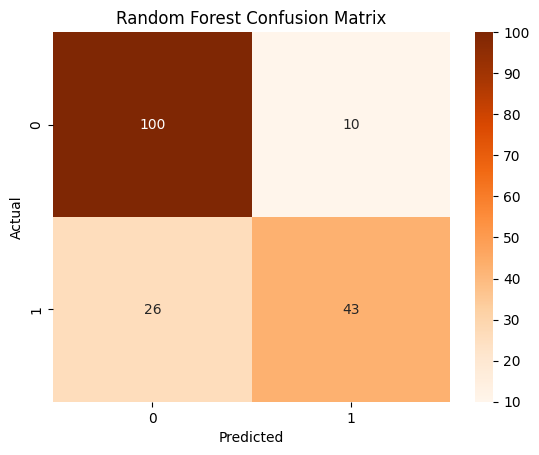

In [48]:
cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [49]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.79      0.91      0.85       110
           1       0.81      0.62      0.70        69

    accuracy                           0.80       179
   macro avg       0.80      0.77      0.78       179
weighted avg       0.80      0.80      0.79       179



In [50]:
feature_importance_rf = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

feature_importance_rf = feature_importance_rf.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_rf)

      Feature  Importance
5    Sex_male    0.438518
4        Fare    0.187870
0      Pclass    0.137479
1         Age    0.121378
2       SibSp    0.041642
3       Parch    0.031704
7  Embarked_S    0.031011
6  Embarked_Q    0.010398


In [51]:
results = pd.DataFrame({
    "Algorithm": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ]
})

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

print(results)

             Algorithm  Accuracy
0  Logistic Regression  0.804469
2        Random Forest  0.798883
1        Decision Tree  0.770950


In [52]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [53]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [54]:
lr_scores = cross_val_score(
    LogisticRegression(max_iter=1000),
    X, y,
    cv=skf,
    scoring="accuracy"
)

print("LR Scores:", lr_scores)
print("LR Mean Accuracy:", lr_scores.mean())

LR Scores: [0.77094972 0.80337079 0.78651685 0.78089888 0.82022472]
LR Mean Accuracy: 0.7923921913250894


In [55]:
dt_scores = cross_val_score(
    DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ),
    X, y,
    cv=skf,
    scoring="accuracy"
)

print("DT Scores:", dt_scores)
print("DT Mean Accuracy:", dt_scores.mean())

DT Scores: [0.83798883 0.81460674 0.79775281 0.82022472 0.8258427 ]
DT Mean Accuracy: 0.8192831586215554


In [56]:
rf_scores = cross_val_score(
    RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42
    ),
    X, y,
    cv=skf,
    scoring="accuracy"
)

print("RF Scores:", rf_scores)
print("RF Mean Accuracy:", rf_scores.mean())

RF Scores: [0.84916201 0.82022472 0.80898876 0.84269663 0.83146067]
RF Mean Accuracy: 0.8305065595380077


In [57]:
cv_results = pd.DataFrame({
    "Algorithm": ["LR", "DT", "RF"],
    "Mean Accuracy": [
        lr_scores.mean(),
        dt_scores.mean(),
        rf_scores.mean()
    ],
    "Std Deviation": [
        lr_scores.std(),
        dt_scores.std(),
        rf_scores.std()
    ]
})

cv_results.sort_values(
    by="Mean Accuracy",
    ascending=False
)

,Algorithm,Mean Accuracy,Std Deviation
2,RF,0.830507,0.014603
1,DT,0.819283,0.013261
0,LR,0.792392,0.017445


In [58]:
models = {
    "LR": LogisticRegression(max_iter=1000),
    "DT": DecisionTreeClassifier(max_depth=5, random_state=42),
    "RF": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
}

for name, model in models.items():

    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)

    print(name)
    print("Training Accuracy:", train_acc)
    print("Validation Accuracy:", test_acc)
    print("---------------------")

LR
Training Accuracy: 0.8075842696629213
Validation Accuracy: 0.8044692737430168
---------------------
DT
Training Accuracy: 0.8651685393258427
Validation Accuracy: 0.7653631284916201
---------------------
RF
Training Accuracy: 0.8792134831460674
Validation Accuracy: 0.7932960893854749
---------------------


In [59]:
results = pd.DataFrame({
    "Algorithm": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [lr_accuracy, dt_accuracy, rf_accuracy]
})

results.sort_values(by="Accuracy", ascending=False)

,Algorithm,Accuracy
0,Logistic Regression,0.804469
2,Random Forest,0.798883
1,Decision Tree,0.770950


In [61]:
#the end